# Step 8 — Forecast business value

**Do XGBoost's improved June transaction forecasts yield better hypothetical preparation decisions than seasonal naive?** Use the existing Step 7 predictions and original recorded line gross profit. No ML model is retrained or regenerated. The oracle knows observed demand and represents an unattainable benchmark.

These are **assumption-dependent decision costs, not actual savings**. June has already been examined in earlier project work, so comparisons are exploratory internal holdouts. This notebook is separate from `04_profit_lab.ipynb` and does not replace it.

In [1]:
from pathlib import Path
import sys, os, json, hashlib
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from forecast_business_value import (run, transaction_economics, load_forecasts, evaluate,
    decision_loss, SHORTAGE_FRACTIONS, WASTE_FRACTIONS, sha)
DATA=Path(os.environ.get('STORIES_DATA','/Users/aya/Downloads/stories_transactions.csv'))
PREDICTIONS=ROOT/'artifacts/daily_demand_models/test_predictions.csv'
OUT=ROOT/'reports/forecast_business_value'
locked=[DATA,PREDICTIONS,*sorted((ROOT/'artifacts/daily_demand_models').glob('*.joblib')),
        ROOT/'reports/demand_forecasting/selection_lock.json']
before={str(p):sha(p) for p in locked}
print('Frozen June forecasts:',PREDICTIONS)
print('Source SHA256:',sha(DATA))
print('Shortage fractions of Jan-May GP/transaction:',SHORTAGE_FRACTIONS)
print('Excess fractions of Jan-May recorded input cost/transaction:',WASTE_FRACTIONS)

Frozen June forecasts: /Users/aya/Downloads/hack/artifacts/daily_demand_models/test_predictions.csv
Source SHA256: f1672e728c28295b2b802d878fd38a158ba039827b429355e8438ee0463237a1
Shortage fractions of Jan-May GP/transaction: (0.25, 0.5, 1.0)
Excess fractions of Jan-May recorded input cost/transaction: (0.1, 0.25, 0.5)


## 1. Historical gross profit per unique transaction

Sum **recorded line gross profit** within transaction ID (after confirming an ID identifies one branch/date), then average transaction totals by branch. Do not average line margins or multiply GP by quantity twice. Retain all recorded rows, consistent with the Step 7 targets; identical line entries have unresolved provenance.

Show Jan–June descriptively, but **use only Jan–May branch economics to set June penalty rates**. June-only economics are a descriptive check, not a pricing input. Recorded input cost = quantity × recorded unit cost; it is not demonstrated avoidable waste.

In [2]:
raw,transactions,economics=transaction_economics(DATA)
display(economics[economics.Period=='Jan-June descriptive'].round(4))
display(economics[economics.Period=='Jan-May calibration'].round(4))
display(economics[economics.Period=='June descriptive'].round(4))
print('Recorded line GP total:',round(raw['Line Gross Profit (USD)'].sum(),2))
print('Grouped transaction GP total:',round(transactions.RecordedGPUSD.sum(),2))
assert np.isclose(raw['Line Gross Profit (USD)'].sum(),transactions.RecordedGPUSD.sum())

Recorded line GP total: 179430.49
Grouped transaction GP total: 179430.49


,Branch,Transactions,RecordedGPUSD,RecordedRevenueUSD,RecordedInputCostUSD,Period,GPPerTransactionUSD,InputCostPerTransactionUSD
6,Garden,11163,46794.49,99748.55,52954.06,Jan-June descriptive,4.1919,4.7437
7,Harbour,16334,97753.94,150483.58,52729.64,Jan-June descriptive,5.9847,3.2282
8,Uptown,6390,34882.06,55693.01,20810.95,Jan-June descriptive,5.4589,3.2568


,Branch,Transactions,RecordedGPUSD,RecordedRevenueUSD,RecordedInputCostUSD,Period,GPPerTransactionUSD,InputCostPerTransactionUSD
0,Garden,8912,37379.76,79613.19,42233.43,Jan-May calibration,4.1943,4.7389
1,Harbour,12948,77249.43,118893.18,41643.75,Jan-May calibration,5.9661,3.2162
2,Uptown,5121,28026.31,44776.68,16750.37,Jan-May calibration,5.4728,3.2709


,Branch,Transactions,RecordedGPUSD,RecordedRevenueUSD,RecordedInputCostUSD,Period,GPPerTransactionUSD,InputCostPerTransactionUSD
3,Garden,2251,9414.73,20135.36,10720.63,June descriptive,4.1825,4.7626
4,Harbour,3386,20504.51,31590.40,11085.89,June descriptive,6.0557,3.2740
5,Uptown,1269,6855.75,10916.33,4060.58,June descriptive,5.4025,3.1998


## 2. Lock the same 90 June branch-days

Use the saved Seasonal naive and XGBoost columns, not refitted or reconstructed predictions. Check all 30 dates × three branches and reconcile targets to source unique transactions. Forecasts were issued after the previous day closed; this is not a month-ahead forecast.

In [3]:
forecasts=load_forecasts(PREDICTIONS,transactions)
display(forecasts.head(15))
display(forecasts.groupby('Branch').agg(Days=('Date','size'),ActualTransactions=('Transactions','sum')))
print('Total branch-days:',len(forecasts))
for model in ['Seasonal naive','XGBoost']:
    print(model,'saved continuous forecast MAE:',np.mean(abs(forecasts[model]-forecasts.Transactions)))

Total branch-days: 90
Seasonal naive saved continuous forecast MAE: 9.6
XGBoost saved continuous forecast MAE: 9.1015335


,Branch,Date,Transactions,Seasonal naive,XGBoost
0,Garden,2026-06-01,82,68.0,70.022354
1,Harbour,2026-06-01,95,88.0,95.512320
2,Uptown,2026-06-01,31,40.0,40.284843
3,Garden,2026-06-02,94,113.0,124.671050
4,Harbour,2026-06-02,177,154.0,144.259430
5,Uptown,2026-06-02,52,70.0,68.065254
6,Garden,2026-06-03,78,65.0,69.223915
7,Harbour,2026-06-03,124,112.0,114.698364
8,Uptown,2026-06-03,40,38.0,41.456936
9,Garden,2026-06-04,57,65.0,70.098460


,Days,ActualTransactions
Branch,,
Garden,30,2251
Harbour,30,3386
Uptown,30,1269


## 3. Define the policy and nine hypothetical cost combinations

Prepare nearest-integer **transaction-equivalent capacity**: `floor(forecast + 0.5)`. This is a proxy, not a SKU preparation plan. Apply the same policy to both models without safety buffers or a June-tuned quantile. Oracle capacity equals actual observed demand.

For each branch, shortage costs are 25%, 50%, or 100% of historical Jan–May GP/transaction. Excess costs are 10%, 25%, or 50% of historical Jan–May recorded input cost/transaction. Evaluate all nine cross-products. These fractions are assumed, not estimated lost-sale or waste rates.

`shortage = max(actual − prepared, 0)`; `excess = max(prepared − actual, 0)`.

`total decision cost = shortage × shortage unit penalty + excess × excess unit penalty`.

No goodwill, fixed operating or model maintenance costs are included; do not interpret these penalty totals as operating profit or actual cash spending.

In [4]:
findings=run(DATA,PREDICTIONS)
unit_costs=pd.read_csv(OUT/'scenario_unit_costs.csv')
display(unit_costs.sort_values(['ShortageFraction','WasteFraction','Branch']).round(4))
print('Penalty rates are fixed across June; no test-period margin calibration.')

   Scenario  Seasonal naive     XGBoost  NaiveMinusXGBoostUSD         Winner
 S0.25_W0.1      761.253908  837.335129            -76.081221 Seasonal naive
S0.25_W0.25      991.660713 1017.717988            -26.057276 Seasonal naive
 S0.25_W0.5     1375.672053 1318.356087             57.315966        XGBoost
  S0.5_W0.1     1368.903281 1554.415019           -185.511738 Seasonal naive
 S0.5_W0.25     1599.310085 1734.797878           -135.487793 Seasonal naive
  S0.5_W0.5     1983.321425 2035.435976            -52.114551 Seasonal naive
    S1_W0.1     2584.202025 2988.574798           -404.372772 Seasonal naive
   S1_W0.25     2814.608829 3168.957657           -354.348827 Seasonal naive
    S1_W0.5     3198.620170 3469.595755           -270.975586 Seasonal naive
Wins: [{'Branch': 'ALL', 'Winner': 'Seasonal naive', 'scenarios': 8}, {'Branch': 'ALL', 'Winner': 'XGBoost', 'scenarios': 1}, {'Branch': 'Garden', 'Winner': 'XGBoost', 'scenarios': 9}, {'Branch': 'Harbour', 'Winner': 'Seasonal nai

,Scenario,Branch,ShortageFraction,WasteFraction,ShortageUnitCostUSD,WasteUnitCostUSD
0,S0.25_W0.1,Garden,0.25,0.10,1.0486,0.4739
1,S0.25_W0.1,Harbour,0.25,0.10,1.4915,0.3216
2,S0.25_W0.1,Uptown,0.25,0.10,1.3682,0.3271
3,S0.25_W0.25,Garden,0.25,0.25,1.0486,1.1847
4,S0.25_W0.25,Harbour,0.25,0.25,1.4915,0.8041
5,S0.25_W0.25,Uptown,0.25,0.25,1.3682,0.8177
6,S0.25_W0.5,Garden,0.25,0.50,1.0486,2.3695
7,S0.25_W0.5,Harbour,0.25,0.50,1.4915,1.6081
8,S0.25_W0.5,Uptown,0.25,0.50,1.3682,1.6355
9,S0.5_W0.1,Garden,0.50,0.10,2.0972,0.4739


## 4. Overall decision costs and dollar differences

Positive **NaiveMinusXGBoostUSD** means XGBoost has lower assumed cost. These are paired comparisons on the same dates. Oracle cost is zero by construction and excludes perfect-information acquisition cost.

In [5]:
summary=pd.read_csv(OUT/'decision_costs.csv')
comparison=pd.read_csv(OUT/'model_comparison.csv')
display(summary[summary.Branch=='ALL'][['Scenario','Model','ShortageCostUSD','OverPreparationCostUSD','TotalDecisionCostUSD']].round(2))
display(comparison[comparison.Branch=='ALL'].sort_values(['ShortageFraction','WasteFraction']).round(4))

,Scenario,Model,ShortageCostUSD,OverPreparationCostUSD,TotalDecisionCostUSD
0,S0.25_W0.1,Oracle,0.00,0.00,0.00
1,S0.25_W0.1,Seasonal naive,607.65,153.60,761.25
2,S0.25_W0.1,XGBoost,717.08,120.26,837.34
3,S0.25_W0.25,Oracle,0.00,0.00,0.00
4,S0.25_W0.25,Seasonal naive,607.65,384.01,991.66
5,S0.25_W0.25,XGBoost,717.08,300.64,1017.72
6,S0.25_W0.5,Oracle,0.00,0.00,0.00
7,S0.25_W0.5,Seasonal naive,607.65,768.02,1375.67
8,S0.25_W0.5,XGBoost,717.08,601.28,1318.36
9,S0.5_W0.1,Oracle,0.00,0.00,0.00


,Branch,Scenario,ShortageFraction,WasteFraction,Oracle,Seasonal naive,XGBoost,XGBoostMinusNaiveUSD,NaiveMinusXGBoostUSD,XGBoostReductionFraction,Winner
0,ALL,S0.25_W0.1,0.25,0.10,0.0,761.2539,837.3351,76.0812,-76.0812,-0.0999,Seasonal naive
1,ALL,S0.25_W0.25,0.25,0.25,0.0,991.6607,1017.7180,26.0573,-26.0573,-0.0263,Seasonal naive
2,ALL,S0.25_W0.5,0.25,0.50,0.0,1375.6721,1318.3561,-57.3160,57.3160,0.0417,XGBoost
3,ALL,S0.5_W0.1,0.50,0.10,0.0,1368.9033,1554.4150,185.5117,-185.5117,-0.1355,Seasonal naive
4,ALL,S0.5_W0.25,0.50,0.25,0.0,1599.3101,1734.7979,135.4878,-135.4878,-0.0847,Seasonal naive
5,ALL,S0.5_W0.5,0.50,0.50,0.0,1983.3214,2035.4360,52.1146,-52.1146,-0.0263,Seasonal naive
6,ALL,S1_W0.1,1.00,0.10,0.0,2584.2020,2988.5748,404.3728,-404.3728,-0.1565,Seasonal naive
7,ALL,S1_W0.25,1.00,0.25,0.0,2814.6088,3168.9577,354.3488,-354.3488,-0.1259,Seasonal naive
8,ALL,S1_W0.5,1.00,0.50,0.0,3198.6202,3469.5958,270.9756,-270.9756,-0.0847,Seasonal naive


## 5. Branch-level results

A global MAE advantage can hide directional errors at one branch. Show both shortage and over-preparation components plus the paired cost difference for every branch and assumption. Do not choose a new branch-specific policy from June and call it independently validated.

In [6]:
for branch in ['Garden','Harbour','Uptown']:
    display(Markdown('### '+branch))
    display(comparison[comparison.Branch==branch].sort_values(['ShortageFraction','WasteFraction']).round(4))
    display(summary[summary.Branch==branch][['Scenario','Model','ShortageCostUSD','OverPreparationCostUSD','TotalDecisionCostUSD']].round(2))
display(pd.DataFrame(findings['wins']))

### Garden

,Branch,Scenario,ShortageFraction,WasteFraction,Oracle,Seasonal naive,XGBoost,XGBoostMinusNaiveUSD,NaiveMinusXGBoostUSD,XGBoostReductionFraction,Winner
9,Garden,S0.25_W0.1,0.25,0.10,0.0,232.2630,197.1559,-35.1071,35.1071,0.1512,XGBoost
10,Garden,S0.25_W0.25,0.25,0.25,0.0,343.1541,315.1555,-27.9987,27.9987,0.0816,XGBoost
11,Garden,S0.25_W0.5,0.25,0.50,0.0,527.9728,511.8215,-16.1513,16.1513,0.0306,XGBoost
12,Garden,S0.5_W0.1,0.50,0.10,0.0,390.5985,315.6454,-74.9531,74.9531,0.1919,XGBoost
13,Garden,S0.5_W0.25,0.50,0.25,0.0,501.4896,433.6449,-67.8447,67.8447,0.1353,XGBoost
14,Garden,S0.5_W0.5,0.50,0.50,0.0,686.3083,630.3109,-55.9973,55.9973,0.0816,XGBoost
15,Garden,S1_W0.1,1.00,0.10,0.0,707.2694,552.6243,-154.6451,154.6451,0.2187,XGBoost
16,Garden,S1_W0.25,1.00,0.25,0.0,818.1606,670.6239,-147.5367,147.5367,0.1803,XGBoost
17,Garden,S1_W0.5,1.00,0.50,0.0,1002.9793,867.2899,-135.6894,135.6894,0.1353,XGBoost


,Scenario,Model,ShortageCostUSD,OverPreparationCostUSD,TotalDecisionCostUSD
27,S0.25_W0.1,Oracle,0.00,0.00,0.00
30,S0.25_W0.1,Seasonal naive,158.34,73.93,232.26
33,S0.25_W0.1,XGBoost,118.49,78.67,197.16
36,S0.25_W0.25,Oracle,0.00,0.00,0.00
39,S0.25_W0.25,Seasonal naive,158.34,184.82,343.15
42,S0.25_W0.25,XGBoost,118.49,196.67,315.16
45,S0.25_W0.5,Oracle,0.00,0.00,0.00
48,S0.25_W0.5,Seasonal naive,158.34,369.64,527.97
51,S0.25_W0.5,XGBoost,118.49,393.33,511.82
54,S0.5_W0.1,Oracle,0.00,0.00,0.00


### Harbour

,Branch,Scenario,ShortageFraction,WasteFraction,Oracle,Seasonal naive,XGBoost,XGBoostMinusNaiveUSD,NaiveMinusXGBoostUSD,XGBoostReductionFraction,Winner
18,Harbour,S0.25_W0.1,0.25,0.10,0.0,334.1794,454.9132,120.7338,-120.7338,-0.3613,Seasonal naive
19,Harbour,S0.25_W0.25,0.25,0.25,0.0,403.6500,479.5174,75.8674,-75.8674,-0.1880,Seasonal naive
20,Harbour,S0.25_W0.5,0.25,0.50,0.0,519.4343,520.5243,1.0900,-1.0900,-0.0021,Seasonal naive
21,Harbour,S0.5_W0.1,0.50,0.10,0.0,622.0451,893.4236,271.3785,-271.3785,-0.4363,Seasonal naive
22,Harbour,S0.5_W0.25,0.50,0.25,0.0,691.5157,918.0278,226.5121,-226.5121,-0.3276,Seasonal naive
23,Harbour,S0.5_W0.5,0.50,0.50,0.0,807.3000,959.0347,151.7348,-151.7348,-0.1880,Seasonal naive
24,Harbour,S1_W0.1,1.00,0.10,0.0,1197.7765,1770.4445,572.6680,-572.6680,-0.4781,Seasonal naive
25,Harbour,S1_W0.25,1.00,0.25,0.0,1267.2471,1795.0487,527.8016,-527.8016,-0.4165,Seasonal naive
26,Harbour,S1_W0.5,1.00,0.50,0.0,1383.0314,1836.0556,453.0243,-453.0243,-0.3276,Seasonal naive


,Scenario,Model,ShortageCostUSD,OverPreparationCostUSD,TotalDecisionCostUSD
28,S0.25_W0.1,Oracle,0.00,0.00,0.00
31,S0.25_W0.1,Seasonal naive,287.87,46.31,334.18
34,S0.25_W0.1,XGBoost,438.51,16.40,454.91
37,S0.25_W0.25,Oracle,0.00,0.00,0.00
40,S0.25_W0.25,Seasonal naive,287.87,115.78,403.65
43,S0.25_W0.25,XGBoost,438.51,41.01,479.52
46,S0.25_W0.5,Oracle,0.00,0.00,0.00
49,S0.25_W0.5,Seasonal naive,287.87,231.57,519.43
52,S0.25_W0.5,XGBoost,438.51,82.01,520.52
55,S0.5_W0.1,Oracle,0.00,0.00,0.00


### Uptown

,Branch,Scenario,ShortageFraction,WasteFraction,Oracle,Seasonal naive,XGBoost,XGBoostMinusNaiveUSD,NaiveMinusXGBoostUSD,XGBoostReductionFraction,Winner
27,Uptown,S0.25_W0.1,0.25,0.10,0.0,194.8115,185.2660,-9.5455,9.5455,0.0490,XGBoost
28,Uptown,S0.25_W0.25,0.25,0.25,0.0,244.8566,223.0451,-21.8114,21.8114,0.0891,XGBoost
29,Uptown,S0.25_W0.5,0.25,0.50,0.0,328.2650,286.0103,-42.2547,42.2547,0.1287,XGBoost
30,Uptown,S0.5_W0.1,0.50,0.10,0.0,356.2597,345.3460,-10.9137,10.9137,0.0306,XGBoost
31,Uptown,S0.5_W0.25,0.50,0.25,0.0,406.3048,383.1251,-23.1796,23.1796,0.0570,XGBoost
32,Uptown,S0.5_W0.5,0.50,0.50,0.0,489.7132,446.0903,-43.6229,43.6229,0.0891,XGBoost
33,Uptown,S1_W0.1,1.00,0.10,0.0,679.1561,665.5060,-13.6501,13.6501,0.0201,XGBoost
34,Uptown,S1_W0.25,1.00,0.25,0.0,729.2011,703.2851,-25.9161,25.9161,0.0355,XGBoost
35,Uptown,S1_W0.5,1.00,0.50,0.0,812.6095,766.2502,-46.3593,46.3593,0.0570,XGBoost


,Scenario,Model,ShortageCostUSD,OverPreparationCostUSD,TotalDecisionCostUSD
29,S0.25_W0.1,Oracle,0.00,0.00,0.00
32,S0.25_W0.1,Seasonal naive,161.45,33.36,194.81
35,S0.25_W0.1,XGBoost,160.08,25.19,185.27
38,S0.25_W0.25,Oracle,0.00,0.00,0.00
41,S0.25_W0.25,Seasonal naive,161.45,83.41,244.86
44,S0.25_W0.25,XGBoost,160.08,62.97,223.05
47,S0.25_W0.5,Oracle,0.00,0.00,0.00
50,S0.25_W0.5,Seasonal naive,161.45,166.82,328.26
53,S0.25_W0.5,XGBoost,160.08,125.93,286.01
56,S0.5_W0.1,Oracle,0.00,0.00,0.00


,Branch,Winner,scenarios
0,ALL,Seasonal naive,8
1,ALL,XGBoost,1
2,Garden,XGBoost,9
3,Harbour,Seasonal naive,9
4,Uptown,XGBoost,9


## 6. Explain directional errors; check rounding sensitivity

The rounding policy makes capacity operationally integral but slightly changes the loss relative to Step 7's continuous MAE. Repeat the same costs with continuous forecasts without selecting whichever presentation looks better. Cost assumptions rescale the same error quantities; nine wins are not nine independent experiments.

Rounding changes winner in 0 of 36 branch/overall scenario comparisons.


,Branch,Model,ShortageTransactions,ExcessTransactions
0,Garden,Oracle,0.0,0.0
1,Garden,Seasonal naive,151.0,156.0
2,Garden,XGBoost,113.0,166.0
3,Harbour,Oracle,0.0,0.0
4,Harbour,Seasonal naive,193.0,144.0
5,Harbour,XGBoost,294.0,51.0
6,Uptown,Oracle,0.0,0.0
7,Uptown,Seasonal naive,118.0,102.0
8,Uptown,XGBoost,117.0,77.0


,Branch,Scenario,ShortageFraction,WasteFraction,Oracle,Seasonal naive,XGBoost,XGBoostMinusNaiveUSD,NaiveMinusXGBoostUSD,XGBoostReductionFraction,Winner
0,ALL,S0.25_W0.1,0.25,0.10,0.0,761.2539,837.6659,76.4120,-76.4120,-0.1004,Seasonal naive
1,ALL,S0.25_W0.25,0.25,0.25,0.0,991.6607,1018.4506,26.7899,-26.7899,-0.0270,Seasonal naive
2,ALL,S0.25_W0.5,0.25,0.50,0.0,1375.6721,1319.7583,-55.9138,55.9138,0.0406,XGBoost
3,ALL,S0.5_W0.1,0.50,0.10,0.0,1368.9033,1554.8088,185.9055,-185.9055,-0.1358,Seasonal naive
4,ALL,S0.5_W0.25,0.50,0.25,0.0,1599.3101,1735.5934,136.2833,-136.2833,-0.0852,Seasonal naive
5,ALL,S0.5_W0.5,0.50,0.50,0.0,1983.3214,2036.9011,53.5797,-53.5797,-0.0270,Seasonal naive
6,ALL,S1_W0.1,1.00,0.10,0.0,2584.2020,2989.0946,404.8925,-404.8925,-0.1567,Seasonal naive
7,ALL,S1_W0.25,1.00,0.25,0.0,2814.6088,3169.8792,355.2703,-355.2703,-0.1262,Seasonal naive
8,ALL,S1_W0.5,1.00,0.50,0.0,3198.6202,3471.1869,272.5667,-272.5667,-0.0852,Seasonal naive


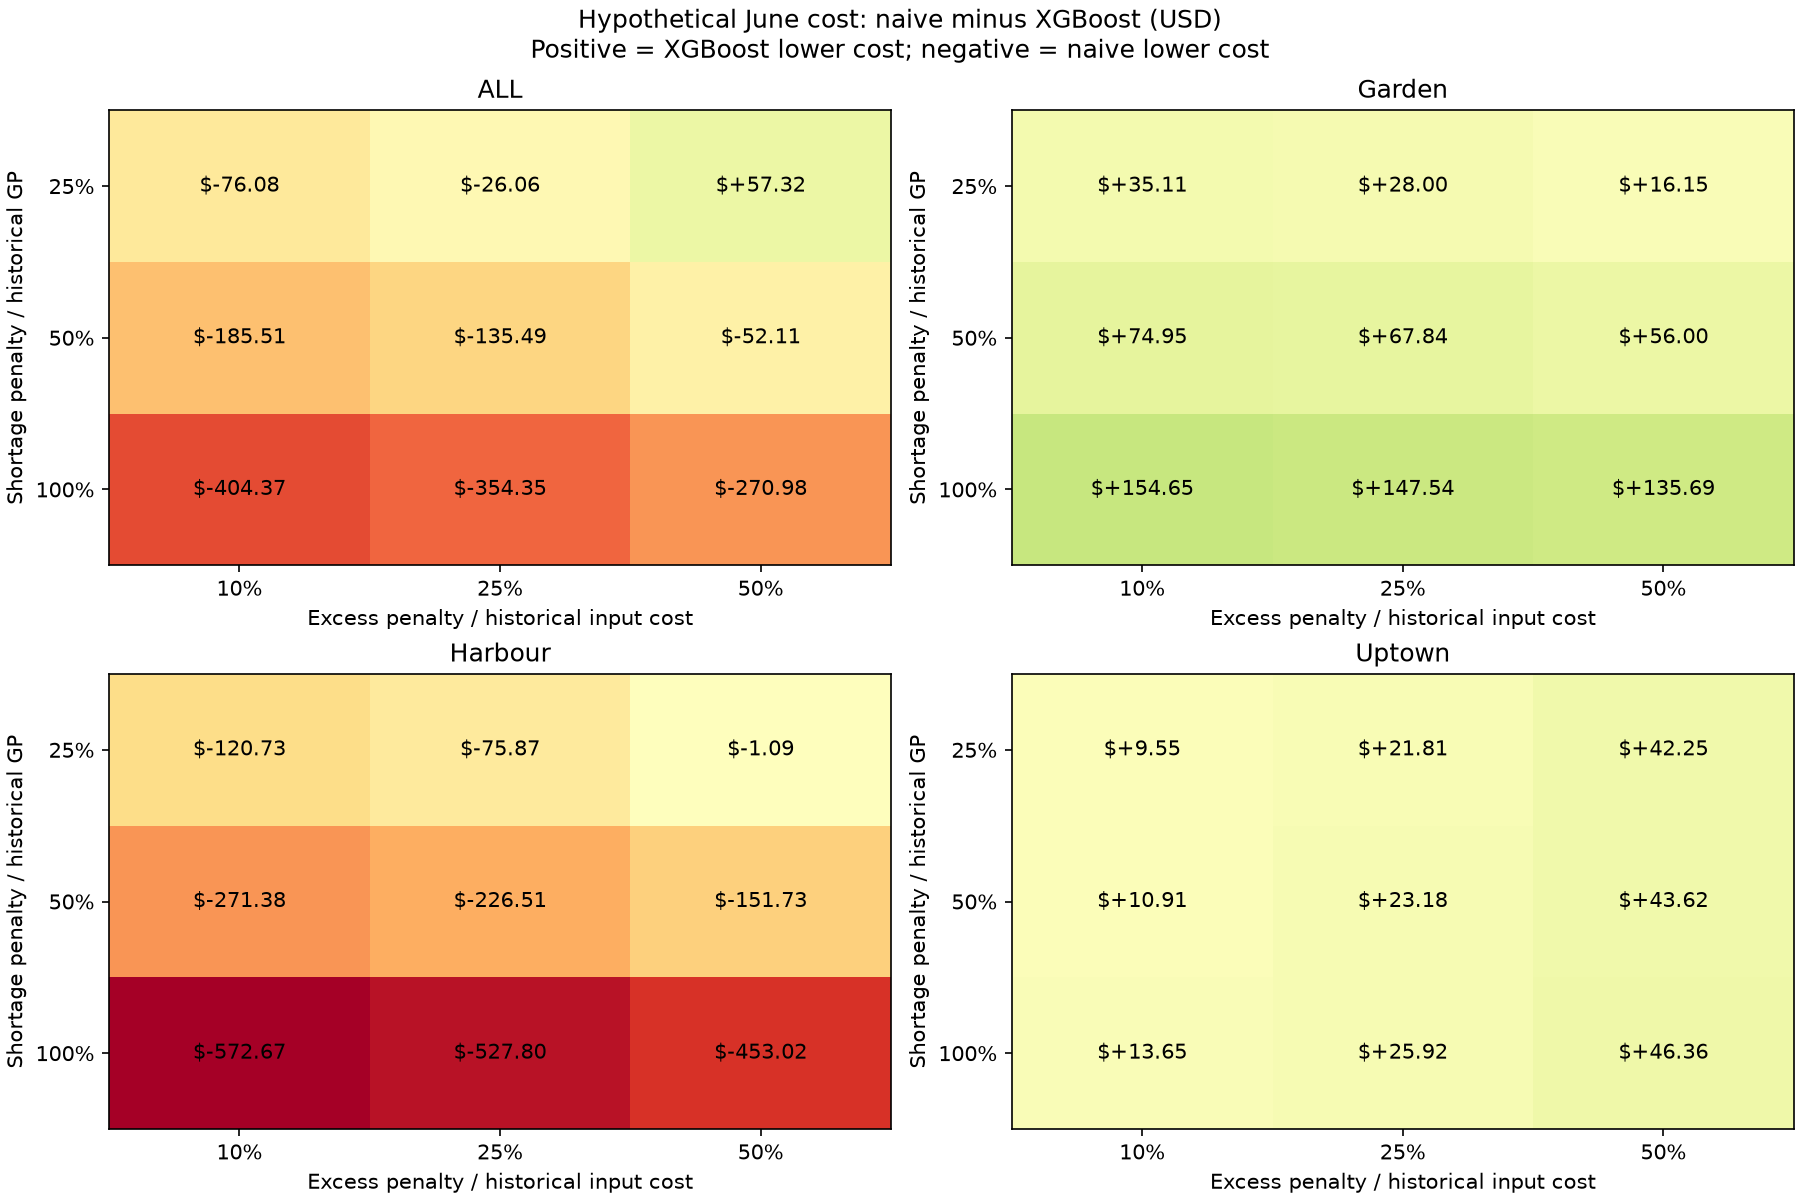

In [7]:
display(pd.read_csv(OUT/'directional_errors.csv'))
continuous=pd.read_csv(OUT/'continuous_model_comparison.csv')
display(continuous[continuous.Branch=='ALL'].round(4))
joined=comparison.merge(continuous,on=['Branch','Scenario'],suffixes=('_integer','_continuous'),validate='one_to_one')
print('Rounding changes winner in',int((joined.Winner_integer!=joined.Winner_continuous).sum()),'of',len(joined),'branch/overall scenario comparisons.')
display(Image(filename=str(ROOT/'figures/forecast_business_value/decision_cost_difference.png')))

## 7. Business interpretation, assumptions and limits

Historical transactions proxy demand; unobserved stockouts may censor it. Recorded gross margin is not contribution after labor and overhead. Aggregate transactions do not reveal SKU requirements, recipe yield, perishability or capacity. The shortage fraction assumes some at-risk sales are lost; the excess fraction assumes some prepared cost is avoidable and unsalvageable. None is observed here.

Use branch differences to form a **prospective hypothesis**, not a new test-selected deployment rule. Verify operational penalties, predefine buffers and any branch-specific selection on earlier data, then shadow-test on later dates. Measure actual stockouts, waste, service and implementation costs. The oracle's zero regret does not mean zero operating cost. No war-response accuracy, causal profit uplift or actual savings is established.

In [8]:
all_rows=comparison[comparison.Branch=='ALL']
print('Overall scenario winners:',all_rows.Winner.value_counts().to_dict())
print('XGBoost lower assumed June cost in every scenario:',bool((all_rows.NaiveMinusXGBoostUSD>0).all()))
for branch in ['Garden','Harbour','Uptown']:
    rows=comparison[comparison.Branch==branch]
    print(branch,'winners:',rows.Winner.value_counts().to_dict(),
          'naive-minus-XGBoost range USD:',round(rows.NaiveMinusXGBoostUSD.min(),2),round(rows.NaiveMinusXGBoostUSD.max(),2))
assert before=={str(p):sha(p) for p in locked}
assert np.allclose(summary.loc[summary.Model=='Oracle','TotalDecisionCostUSD'],0)
print('PASS: source, saved forecasts, selection lock and saved models unchanged; no retraining.')
print('Outputs:',OUT)
print('All dollar differences are hypothetical decision-cost comparisons, not actual savings.')

Overall scenario winners: {'Seasonal naive': 8, 'XGBoost': 1}
XGBoost lower assumed June cost in every scenario: False
Garden winners: {'XGBoost': 9} naive-minus-XGBoost range USD: 16.15 154.65
Harbour winners: {'Seasonal naive': 9} naive-minus-XGBoost range USD: -572.67 -1.09
Uptown winners: {'XGBoost': 9} naive-minus-XGBoost range USD: 9.55 46.36
PASS: source, saved forecasts, selection lock and saved models unchanged; no retraining.
Outputs: /Users/aya/Downloads/hack/reports/forecast_business_value
All dollar differences are hypothetical decision-cost comparisons, not actual savings.
